In [276]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Text(0, 0.5, 'Y Dataset')

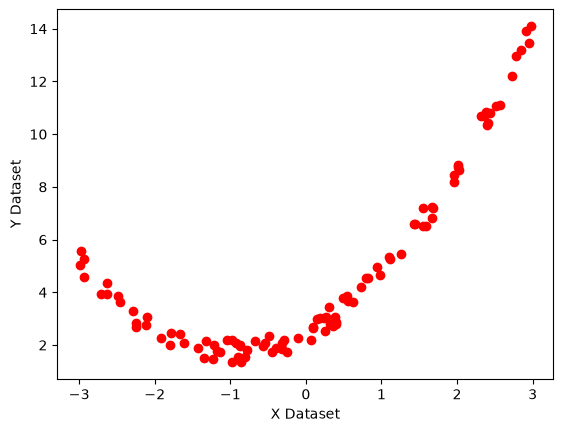

In [277]:
#My train data
x=6*np.random.rand(100,1)-3
y=0.8 * x ** 2 + 1.5 * x + 2 + np.random.rand(100,1)
plt.scatter(x,y,color="r")
plt.xlabel("X Dataset")
plt.ylabel("Y Dataset")

In [278]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=23)
print(X_train.shape)
print(X_test.shape)

(80, 1)
(20, 1)


In [279]:
from sklearn.linear_model import LinearRegression
regression_1=LinearRegression()
regression_1.fit(X_train,y_train)
regression_1

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [280]:
from sklearn.metrics import r2_score
score=r2_score(y_test,regression_1.predict(X_test))
print(score)

0.5805612105701993


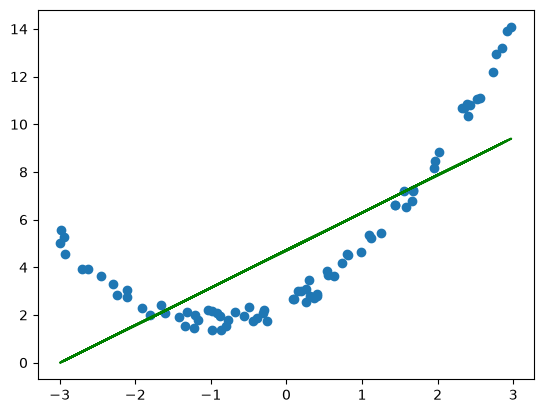

In [281]:
plt.plot(X_train,regression_1.predict(X_train),color="g")
plt.scatter(X_train,y_train)

In [282]:
#Applay Ploinomial
from sklearn.preprocessing import PolynomialFeatures


In [283]:
poly=PolynomialFeatures(degree=2,include_bias=True)
X_train_poly=poly.fit_transform(X_train)
X_test_poly=poly.transform(X_test)

In [284]:
X_train_poly

array([[ 1.00000000e+00,  5.38253594e-01,  2.89716931e-01],
       [ 1.00000000e+00,  1.67187265e+00,  2.79515814e+00],
       [ 1.00000000e+00,  2.35345443e+00,  5.53874774e+00],
       [ 1.00000000e+00, -8.74036925e-01,  7.63940547e-01],
       [ 1.00000000e+00, -2.99215772e+00,  8.95300783e+00],
       [ 1.00000000e+00,  8.16104432e-01,  6.66026445e-01],
       [ 1.00000000e+00,  2.99771522e-01,  8.98629656e-02],
       [ 1.00000000e+00,  3.59377160e-01,  1.29151943e-01],
       [ 1.00000000e+00,  2.91752067e+00,  8.51192685e+00],
       [ 1.00000000e+00,  8.79556363e-02,  7.73619396e-03],
       [ 1.00000000e+00,  1.67521252e+00,  2.80633697e+00],
       [ 1.00000000e+00, -1.61011185e+00,  2.59246017e+00],
       [ 1.00000000e+00,  2.51527305e+00,  6.32659853e+00],
       [ 1.00000000e+00, -1.65880950e+00,  2.75164894e+00],
       [ 1.00000000e+00,  2.32182513e+00,  5.39087194e+00],
       [ 1.00000000e+00, -2.98168567e+00,  8.89044946e+00],
       [ 1.00000000e+00,  1.55385954e+00

In [285]:
regression=LinearRegression()
regression.fit(X_train_poly,y_train)
y_pred=regression.predict(X_test_poly)
score=r2_score(y_test,y_pred)
score

0.993804267691134

In [286]:
regression.coef_

array([[0.        , 1.51012443, 0.79332426]])

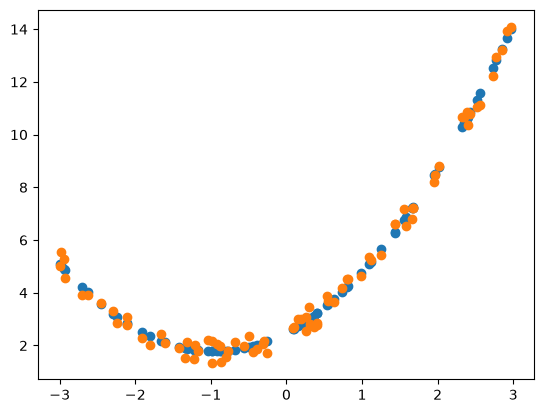

In [287]:
plt.scatter(X_train,regression.predict(X_train_poly))
plt.scatter(X_train,y_train)

In [288]:
from sklearn.pipeline import Pipeline

In [289]:
def poly_regression(degree):
    X_new = np.linspace(-3, 3, 200).reshape(200, 1)
    
    poly_features=PolynomialFeatures(degree=degree,include_bias=True)
    lin_reg=LinearRegression()
    poly_regression=Pipeline([
        ("poly_features",poly_features),
        ("lin_reg",lin_reg)
    ])
    poly_regression.fit(X_train,y_train) ## ploynomial and fit of linear reression
    y_pred_new=poly_regression.predict(X_new)
    #plotting prediction line
    plt.plot(X_new, y_pred_new,'r', label="Degree " + str(degree), linewidth=2)
    plt.plot(X_train, y_train, "b.", linewidth=3)
    plt.plot(X_test, y_test, "g.", linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.axis([-4,4, 0, 10])
    plt.show()

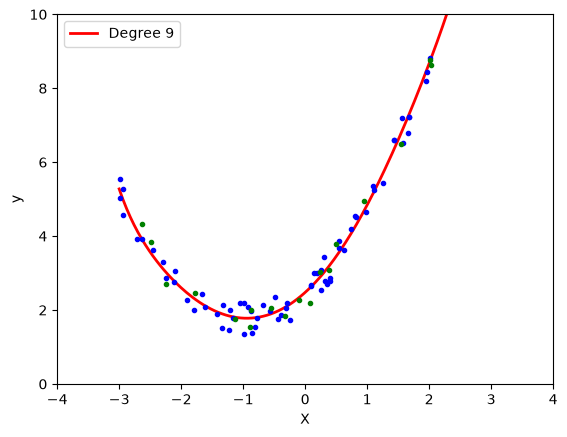

In [290]:
poly_regression(9)